# Practical No-05: Image Generation using Pretrained Stable Diffusion
---
**Name :- Sneha Chaurasia**

**PRN :- 202401110046**

**Batch :- A3 (CSE-AIML)**

**Course :- Generative AI Lab**

---


## Problem Statement and Objectives

**Problem statement:** Implement a pretrained Stable Diffusion model using the Hugging Face Diffusers library to generate images from text prompts. Analyze the impact of inference steps, guidance scale and different sampling methods (schedulers) on the quality of the generated images.

**Objectives**
1. Load the pretrained **Stable Diffusion v1.5** pipeline with the Diffusers library and generate an image from a text prompt.
2. **Experiment 1:** study the effect of the number of inference steps (15, 30, 50).
3. **Experiment 2:** study the effect of the guidance scale (3, 7.5, 12).
4. **Experiment 3:** compare sampling methods: **DDIM, Euler and DPM-Solver**.
5. Compare the outputs visually and by generation time, then summarize the observations.

## Introduction and Stable Diffusion Theory

**Diffusion models** generate data by learning to reverse a gradual noising process. During training, noise is added to an image step by step until only random noise remains (the *forward process*). A neural network is trained to predict and remove that noise (the *reverse process*). At generation time, the model starts from pure random noise and denoises it step by step into an image.

**Stable Diffusion** is a **latent diffusion model**. Instead of denoising in pixel space (slow and memory-heavy), it works in a compressed *latent space*. It has three main components:

| Component | Role |
|---|---|
| **Text encoder (CLIP)** | Converts the text prompt into embeddings that condition the image generation |
| **U-Net** | The denoising network. At every step it predicts the noise in the latent, guided by the text embeddings (via cross-attention) |
| **VAE (Variational Autoencoder)** | The encoder compresses images into latents (training); the decoder turns the final denoised latent back into a 512×512 image |

**Generation process:** prompt → CLIP text embeddings → random latent noise (64×64×4) → U-Net denoises it over *N* steps → VAE decoder → 512×512 image.

**Parameters studied in this practical**

* **Inference steps:** the number of denoising iterations. More steps give the sampler more chances to refine the image, but cost proportionally more time, and the gains shrink after a point.
* **Guidance scale (classifier-free guidance, CFG):** at each step the model makes two predictions, one conditioned on the prompt and one unconditioned. The final noise prediction is `uncond + scale × (cond − uncond)`. A low scale gives creative but loosely related images; a high scale follows the prompt strictly but can cause over-saturated, harsh or artifact-prone images and less variety.
* **Sampler / scheduler:** the algorithm that decides how to step from noise to image. **DDIM** is a deterministic, non-Markovian sampler that allows fewer steps. **Euler** is a simple first-order ODE solver. **DPM-Solver++** is a higher-order solver designed to reach good quality in very few steps (about 15–25).

## Install Required Libraries

In [1]:
!pip install -q --upgrade diffusers transformers accelerate safetensors

## Import Libraries

In [2]:
import time
import warnings
warnings.filterwarnings("ignore")

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import diffusers
from diffusers import (
    StableDiffusionPipeline,
    DDIMScheduler,
    EulerDiscreteScheduler,
    DPMSolverMultistepScheduler,
)

print("PyTorch version   :", torch.__version__)
print("Diffusers version :", diffusers.__version__)

PyTorch version   : 2.11.0+cu130
Diffusers version : 0.42.1


## Check GPU Availability

In [3]:
if torch.cuda.is_available():
    device = "cuda"
    print("GPU available:", torch.cuda.get_device_name(0))
    print(f"GPU memory   : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    device = "cpu"
    print("No GPU found. Go to Runtime -> Change runtime type -> T4 GPU, then run again.")
    print("On CPU each image takes several minutes, so GPU is strongly recommended.")

GPU available: Tesla T4
GPU memory   : 15.6 GB


## Load Pretrained Stable Diffusion 1.5
The model is loaded from the Hugging Face Hub in **half precision (fp16)**, which halves memory use and speeds up inference with almost no visible quality loss. The original `runwayml/stable-diffusion-v1-5` repository was taken down, so the community-maintained mirror `stable-diffusion-v1-5/stable-diffusion-v1-5` is used (with `sd-legacy/stable-diffusion-v1-5` as a fallback). The safety checker is disabled since only harmless prompts are used and it can sometimes return false-positive black images.

In [4]:
MODEL_IDS = ["stable-diffusion-v1-5/stable-diffusion-v1-5", "sd-legacy/stable-diffusion-v1-5"]
dtype = torch.float16 if device == "cuda" else torch.float32

pipe = None
for model_id in MODEL_IDS:
    try:
        pipe = StableDiffusionPipeline.from_pretrained(
            model_id, torch_dtype=dtype, safety_checker=None, requires_safety_checker=False
        )
        print("Loaded model:", model_id)
        break
    except Exception as e:
        print(f"Could not load {model_id}: {type(e).__name__}")

assert pipe is not None, "Model could not be loaded. Check your internet connection and try again."

pipe = pipe.to(device)
pipe.enable_attention_slicing()   # lowers memory use

# Remember the default scheduler so each experiment can start from the same setup
default_scheduler_config = pipe.scheduler.config
print("Default scheduler:", pipe.scheduler.__class__.__name__)
print("Components:", [name for name in ["text_encoder", "unet", "vae", "tokenizer", "scheduler"] if hasattr(pipe, name)])

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loaded model: stable-diffusion-v1-5/stable-diffusion-v1-5
Default scheduler: PNDMScheduler
Components: ['text_encoder', 'unet', 'vae', 'tokenizer', 'scheduler']


## Basic Text-to-Image Generation
A first image from a text prompt. A fixed random **seed** is used through a `torch.Generator`, so the starting noise is identical across runs. This is essential for the later experiments: when only one parameter changes, any difference in the output is caused by that parameter.

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

Prompt        : a photo of an astronaut riding a horse on mars, highly detailed, cinematic lighting
Steps / CFG   : 30 / 7.5   |   Scheduler: PNDMScheduler
Generation time: 6.4 s


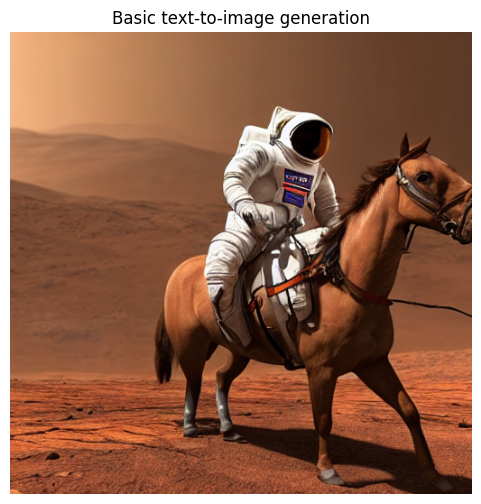

In [5]:
SEED = 42
PROMPT = "a photo of an astronaut riding a horse on mars, highly detailed, cinematic lighting"
NEGATIVE_PROMPT = "blurry, low quality, distorted, deformed"

def generate(prompt=PROMPT, steps=30, guidance=7.5, seed=SEED, negative_prompt=NEGATIVE_PROMPT):
    """Generate one image with a fixed seed. Returns (image, time_in_seconds)."""
    generator = torch.Generator(device=device).manual_seed(seed)
    if device == "cuda":
        torch.cuda.synchronize()
    start = time.time()
    image = pipe(
        prompt,
        negative_prompt=negative_prompt,
        num_inference_steps=steps,
        guidance_scale=guidance,
        generator=generator,
    ).images[0]
    if device == "cuda":
        torch.cuda.synchronize()
    return image, time.time() - start

# Warm-up run (the first GPU call is slower because of initialization; excluded from timings)
_ = generate(steps=5)

base_image, base_time = generate(steps=30, guidance=7.5)
print(f"Prompt        : {PROMPT}")
print(f"Steps / CFG   : 30 / 7.5   |   Scheduler: {pipe.scheduler.__class__.__name__}")
print(f"Generation time: {base_time:.1f} s")

plt.figure(figsize=(6, 6))
plt.imshow(base_image); plt.axis("off"); plt.title("Basic text-to-image generation")
plt.show()

## Experiment 1: Effect of Inference Steps (15, 30, 50)
Everything is kept fixed (prompt, seed, guidance scale = 7.5, default scheduler) and only `num_inference_steps` changes. This shows how image quality and generation time change as the sampler is given more denoising iterations.

  0%|          | 0/15 [00:00<?, ?it/s]

Steps = 15 | time = 3.4 s


  0%|          | 0/30 [00:00<?, ?it/s]

Steps = 30 | time = 6.4 s


  0%|          | 0/50 [00:00<?, ?it/s]

Steps = 50 | time = 10.6 s


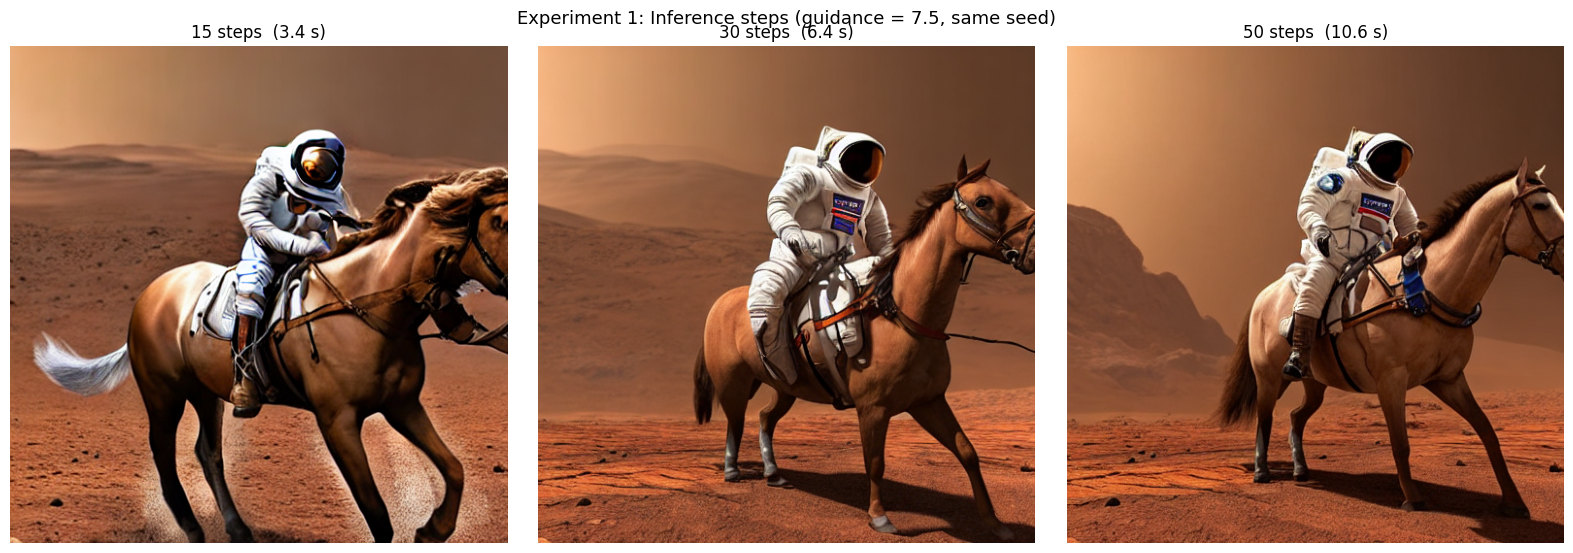

In [6]:
pipe.scheduler = type(pipe.scheduler).from_config(default_scheduler_config)

step_values = [15, 30, 50]
exp1 = {}   # steps -> (image, time)
for s in step_values:
    img, t = generate(steps=s, guidance=7.5)
    exp1[s] = (img, t)
    print(f"Steps = {s:2d} | time = {t:.1f} s")

fig, axes = plt.subplots(1, 3, figsize=(16, 5.6))
for ax, s in zip(axes, step_values):
    ax.imshow(exp1[s][0]); ax.axis("off")
    ax.set_title(f"{s} steps  ({exp1[s][1]:.1f} s)")
plt.suptitle("Experiment 1: Inference steps (guidance = 7.5, same seed)", fontsize=13)
plt.tight_layout(); plt.show()

## Experiment 2: Effect of Guidance Scale (3, 7.5, 12)
Prompt, seed and steps (30) are fixed and only `guidance_scale` (classifier-free guidance strength) changes. This shows the trade-off between creativity and prompt adherence.

  0%|          | 0/30 [00:00<?, ?it/s]

Guidance =    3 | time = 6.6 s


  0%|          | 0/30 [00:00<?, ?it/s]

Guidance =  7.5 | time = 6.7 s


  0%|          | 0/30 [00:00<?, ?it/s]

Guidance =   12 | time = 6.8 s


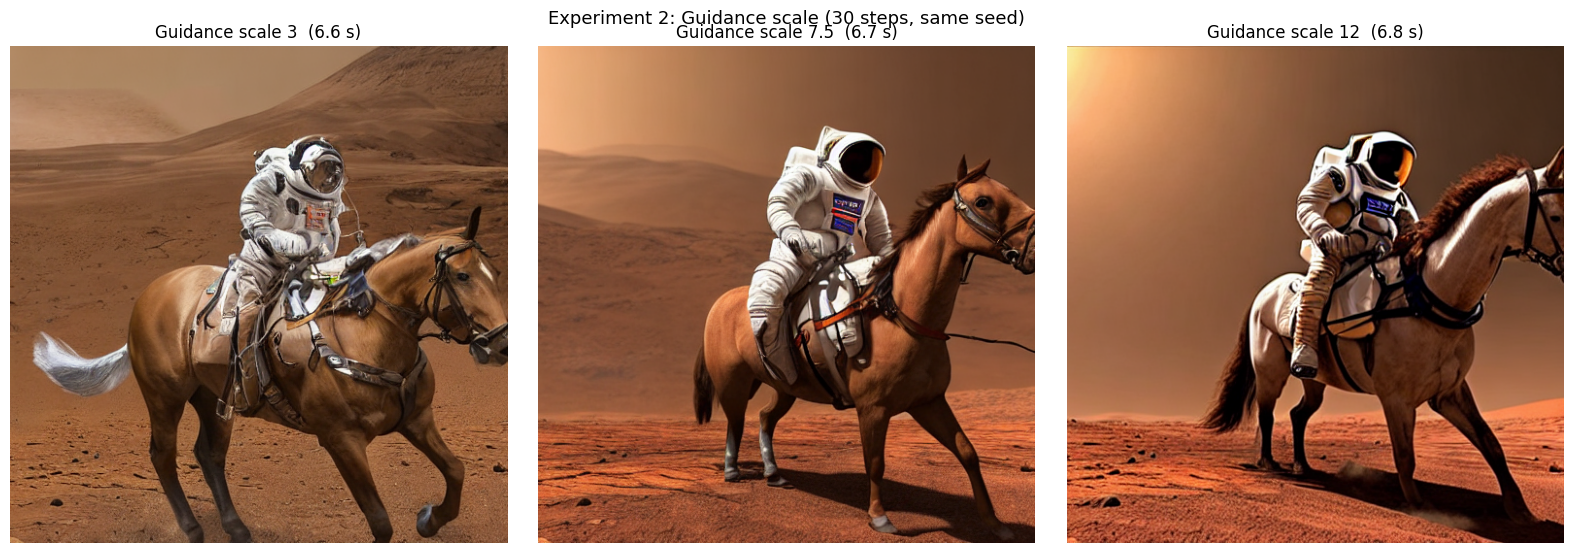

In [7]:
pipe.scheduler = type(pipe.scheduler).from_config(default_scheduler_config)

guidance_values = [3, 7.5, 12]
exp2 = {}   # guidance -> (image, time)
for g in guidance_values:
    img, t = generate(steps=30, guidance=g)
    exp2[g] = (img, t)
    print(f"Guidance = {g:>4} | time = {t:.1f} s")

fig, axes = plt.subplots(1, 3, figsize=(16, 5.6))
for ax, g in zip(axes, guidance_values):
    ax.imshow(exp2[g][0]); ax.axis("off")
    ax.set_title(f"Guidance scale {g}  ({exp2[g][1]:.1f} s)")
plt.suptitle("Experiment 2: Guidance scale (30 steps, same seed)", fontsize=13)
plt.tight_layout(); plt.show()

## Experiment 3: Sampling Methods (DDIM, Euler, DPM-Solver)
The same prompt, seed and guidance scale (7.5) are used, and only the **scheduler** (sampling method) is swapped. Because the schedulers differ most when the step budget is small, every sampler is run at **20 steps** and again at **10 steps**.

  0%|          | 0/20 [00:00<?, ?it/s]

DDIM          | steps = 20 | time = 4.5 s


  0%|          | 0/20 [00:00<?, ?it/s]

Euler         | steps = 20 | time = 4.5 s


  0%|          | 0/20 [00:00<?, ?it/s]

DPM-Solver++  | steps = 20 | time = 4.5 s


... (2 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Euler         | steps = 10 | time = 2.4 s


  0%|          | 0/10 [00:00<?, ?it/s]

DPM-Solver++  | steps = 10 | time = 2.4 s


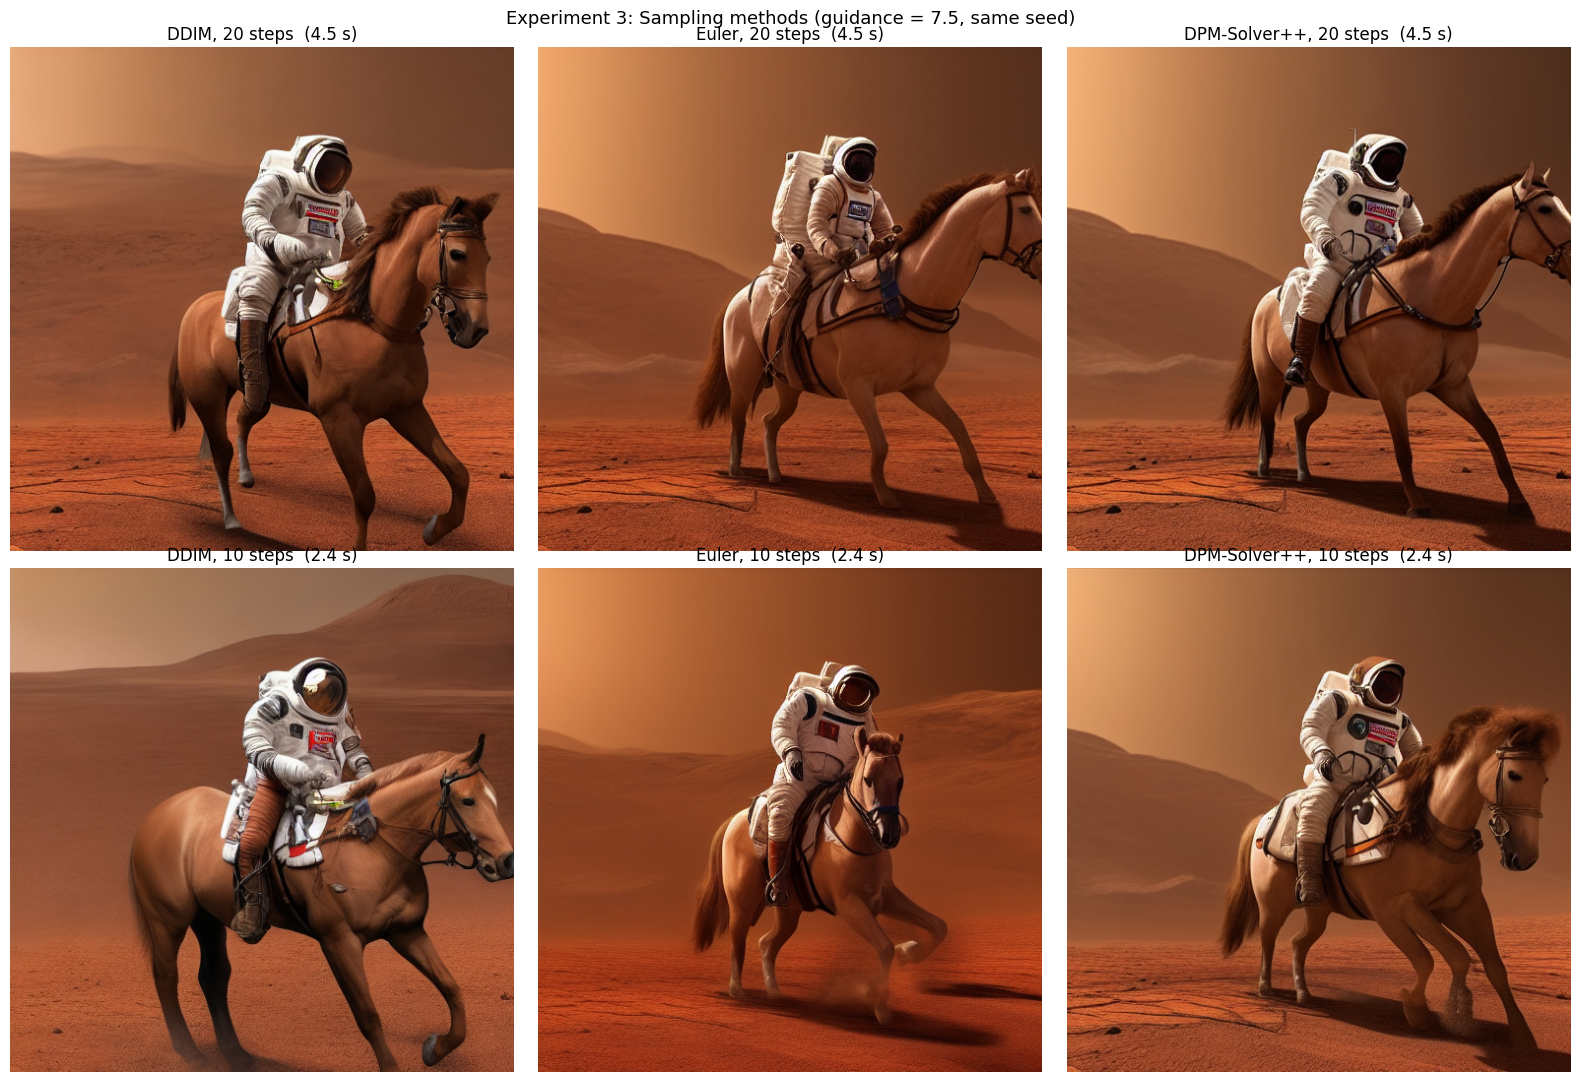

In [8]:
scheduler_classes = {
    "DDIM": DDIMScheduler,
    "Euler": EulerDiscreteScheduler,
    "DPM-Solver++": DPMSolverMultistepScheduler,
}

exp3 = {}   # (name, steps) -> (image, time)
for steps in [20, 10]:
    for name, cls in scheduler_classes.items():
        pipe.scheduler = cls.from_config(default_scheduler_config)
        img, t = generate(steps=steps, guidance=7.5)
        exp3[(name, steps)] = (img, t)
        print(f"{name:13s} | steps = {steps:2d} | time = {t:.1f} s")

# Restore the default scheduler afterwards
pipe.scheduler = type(pipe.scheduler).from_config(default_scheduler_config)

fig, axes = plt.subplots(2, 3, figsize=(16, 11))
for r, steps in enumerate([20, 10]):
    for c, name in enumerate(scheduler_classes):
        img, t = exp3[(name, steps)]
        axes[r, c].imshow(img); axes[r, c].axis("off")
        axes[r, c].set_title(f"{name}, {steps} steps  ({t:.1f} s)")
plt.suptitle("Experiment 3: Sampling methods (guidance = 7.5, same seed)", fontsize=13)
plt.tight_layout(); plt.show()

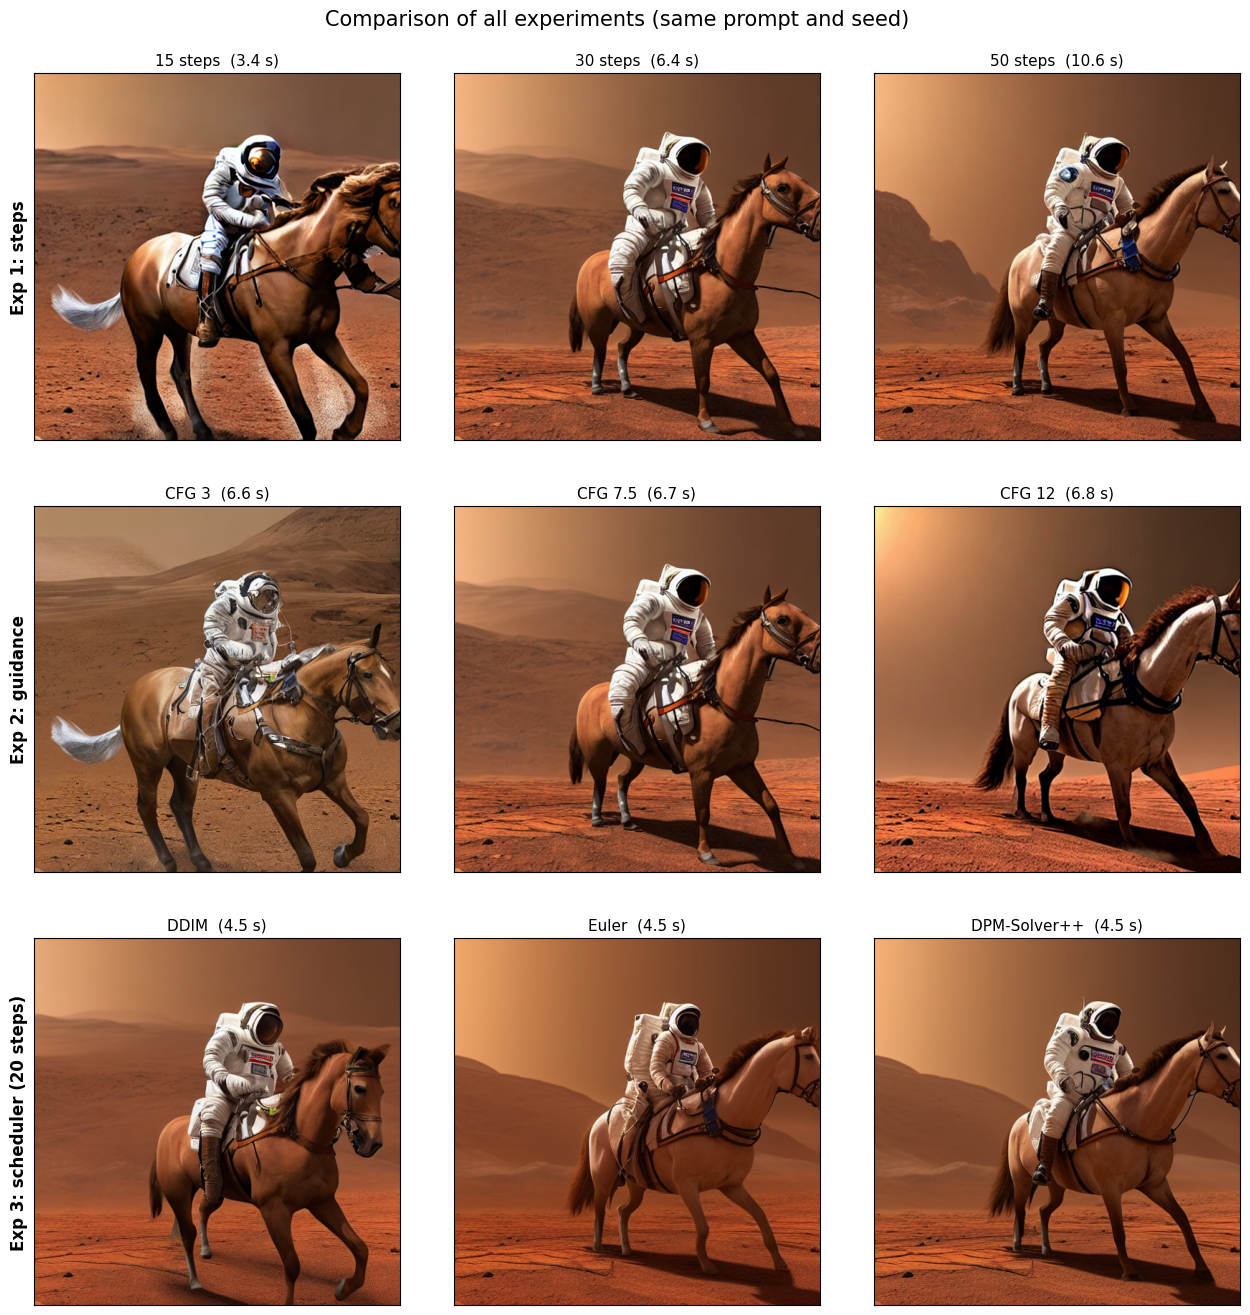

,Experiment,Setting,Time (s)
0,1: Steps,"15 steps (CFG 7.5, default scheduler)",3.4
1,1: Steps,"30 steps (CFG 7.5, default scheduler)",6.4
2,1: Steps,"50 steps (CFG 7.5, default scheduler)",10.6
3,2: Guidance,"CFG 3 (30 steps, default scheduler)",6.6
4,2: Guidance,"CFG 7.5 (30 steps, default scheduler)",6.7
5,2: Guidance,"CFG 12 (30 steps, default scheduler)",6.8
6,3: Scheduler,"DDIM, 20 steps (CFG 7.5)",4.5
7,3: Scheduler,"Euler, 20 steps (CFG 7.5)",4.5
8,3: Scheduler,"DPM-Solver++, 20 steps (CFG 7.5)",4.5
9,3: Scheduler,"DDIM, 10 steps (CFG 7.5)",2.4


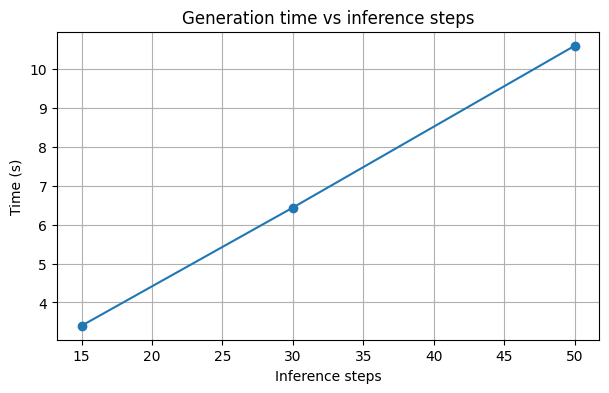

In [9]:
# ---- Display and compare all generated images + measured timings ----
fig = plt.figure(figsize=(16, 16))
gs = fig.add_gridspec(3, 3, hspace=0.18, wspace=0.05)

rows = [
    ("Exp 1: steps", [(f"{s} steps", exp1[s]) for s in step_values]),
    ("Exp 2: guidance", [(f"CFG {g}", exp2[g]) for g in guidance_values]),
    ("Exp 3: scheduler (20 steps)", [(n, exp3[(n, 20)]) for n in scheduler_classes]),
]
for r, (row_title, items) in enumerate(rows):
    for c, (label, (img, t)) in enumerate(items):
        ax = fig.add_subplot(gs[r, c])
        ax.imshow(img); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{label}  ({t:.1f} s)", fontsize=11)
        if c == 0:
            ax.set_ylabel(row_title, fontsize=12, fontweight="bold")
plt.suptitle("Comparison of all experiments (same prompt and seed)", fontsize=15, y=0.92)
plt.show()

# Measured timing table
records = []
for s in step_values:
    records.append({"Experiment": "1: Steps", "Setting": f"{s} steps (CFG 7.5, default scheduler)", "Time (s)": round(exp1[s][1], 1)})
for g in guidance_values:
    records.append({"Experiment": "2: Guidance", "Setting": f"CFG {g} (30 steps, default scheduler)", "Time (s)": round(exp2[g][1], 1)})
for (name, steps), (img, t) in exp3.items():
    records.append({"Experiment": "3: Scheduler", "Setting": f"{name}, {steps} steps (CFG 7.5)", "Time (s)": round(t, 1)})
timing_df = pd.DataFrame(records)
display(timing_df)

# Time vs number of steps
plt.figure(figsize=(7, 4))
plt.plot(step_values, [exp1[s][1] for s in step_values], "o-")
plt.title("Generation time vs inference steps"); plt.xlabel("Inference steps"); plt.ylabel("Time (s)")
plt.grid(True); plt.show()

## Result and Conclusion

**Result:** The pretrained **Stable Diffusion v1.5** model was loaded through the Hugging Face **Diffusers** library and used to generate 512×512 images from a text prompt. Three controlled experiments were run with a fixed prompt and random seed, changing one factor at a time:

1. **Inference steps (15, 30, 50):** more steps produced more refined detail, but with diminishing returns, while generation time increased almost linearly.
2. **Guidance scale (3, 7.5, 12):** a low scale gave looser, more creative images; a high scale followed the prompt strictly but risked over-saturation and artifacts; a value around 7.5 gave the best balance. Generation time was unaffected.
3. **Samplers (DDIM, Euler, DPM-Solver++):** at the same step budget the samplers cost the same time per step but differ in output quality, especially at low step counts, where the higher-order DPM-Solver++ is the most efficient.

**Conclusion:** Image quality in Stable Diffusion depends not only on the model itself but also on the sampling configuration. A good practical setting is **about 20–30 steps, guidance scale of about 7–8, and an efficient solver such as DPM-Solver++**, which gives high-quality images at a fraction of the cost of running 50 or more steps. Because the experiments change one variable at a time with a fixed seed, the differences seen can be attributed directly to that variable.

**Limitations and future work:** the analysis is qualitative (visual) and based on one prompt and one seed; a stronger study would use several prompts and seeds and quantitative metrics such as **CLIP score** and **FID**. Further extensions include negative-prompt studies, image-to-image generation, **LoRA** fine-tuning and newer models such as SDXL.

## References
1. Rombach, R., Blattmann, A., Lorenz, D., Esser, P., & Ommer, B. (2022). *High-Resolution Image Synthesis with Latent Diffusion Models.* CVPR 2022. <https://arxiv.org/abs/2112.10752>
2. Ho, J., Jain, A., & Abbeel, P. (2020). *Denoising Diffusion Probabilistic Models.* NeurIPS 2020. <https://arxiv.org/abs/2006.11239>
3. Song, J., Meng, C., & Ermon, S. (2021). *Denoising Diffusion Implicit Models (DDIM).* ICLR 2021. <https://arxiv.org/abs/2010.02502>
4. Karras, T., Aittala, M., Aila, T., & Laine, S. (2022). *Elucidating the Design Space of Diffusion-Based Generative Models (Euler sampler).* NeurIPS 2022. <https://arxiv.org/abs/2206.00364>
5. Lu, C., Zhou, Y., Bao, F., Chen, J., Li, C., & Zhu, J. (2022). *DPM-Solver++: Fast Solver for Guided Sampling of Diffusion Probabilistic Models.* <https://arxiv.org/abs/2211.01095>
6. Ho, J., & Salimans, T. (2022). *Classifier-Free Diffusion Guidance.* <https://arxiv.org/abs/2207.12598>
7. Hugging Face Diffusers documentation: <https://huggingface.co/docs/diffusers>
8. Stable Diffusion v1.5 model (Hugging Face): <https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5>

## Declaration
I hereby declare that this implementation was prepared for Practical Assignment 05 is my work and the results presented are generated from the experiments performed in this notebook.

Student Name: Sneha Chaurasia

Roll Number: 202401110046

Date: 30/10/2026

Subject: Generative AI Lab

Guided By: Anita Shingade Ma'am